<a href="https://colab.research.google.com/github/gayathridevies-arch/Molecular-Structure-Screener/blob/main/Molecular_Structure_Screener.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES,Molecule
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl,
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl,
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl,
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl,
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl,
...,...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC),
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C,
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O,
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O,

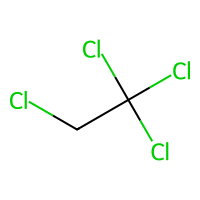
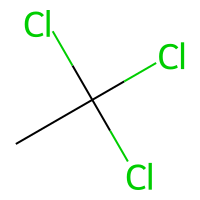
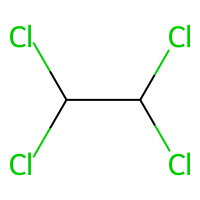
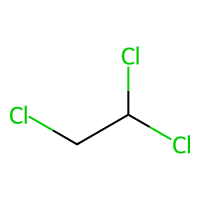
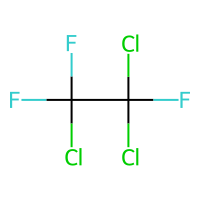
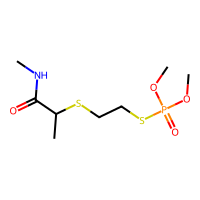
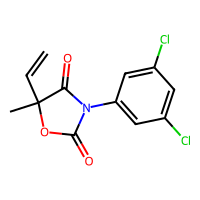
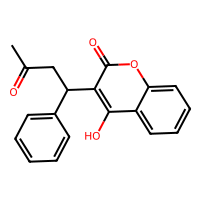
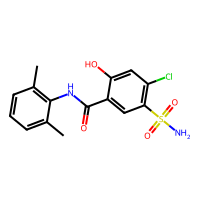
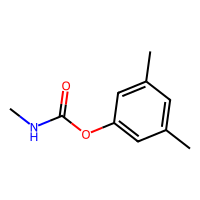

,Molecule,Has_Benzene,Has_Carbonyl,Has_Hydroxyl
0,,False,False,False
1,,False,False,False
2,,False,False,False
3,,False,False,False
4,,False,False,False
...,...,...,...,...
1139,,False,True,False
1140,,True,True,False
1141,,True,True,True
1142,,True,True,True

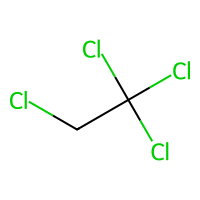
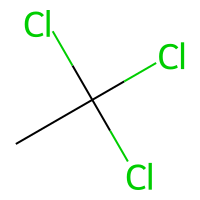
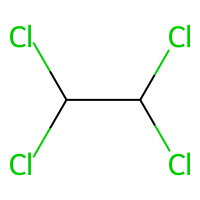
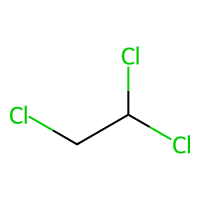
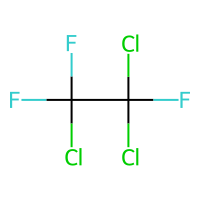
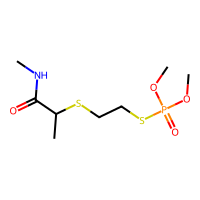
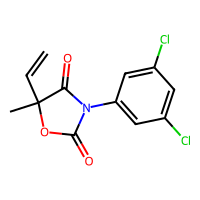
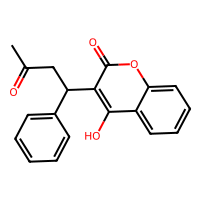
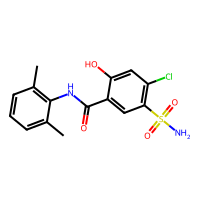
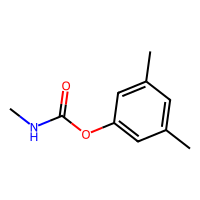

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES,Molecule,Has_Benzene,Has_Carbonyl,Has_Hydroxyl
8,"1,2,3,4-Tetrachlorobenzene",-4.570,-4.546,Clc1ccc(Cl)c(Cl)c1Cl,,True,False,False
9,"1,2,3,4-Tetrahydronapthalene",-4.370,-3.447,C1CCc2ccccc2C1,,True,False,False
10,"1,2,3,5-Tetrachlorobenzene",-4.630,-4.621,Clc1cc(Cl)c(Cl)c(Cl)c1,,True,False,False
11,"1,2,3-Trichlorobenzene",-4.000,-4.008,Clc1cccc(Cl)c1Cl,,True,False,False
12,"1,2,3-Trimethylbenzene",-3.200,-3.312,Cc1cccc(C)c1C,,True,False,False
...,...,...,...,...,...,...,...,...
1133,Triphenylene,-6.726,-5.568,c1ccc2c(c1)c3ccccc3c4ccccc24,,True,False,False
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C,,True,True,False
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O,,True,True,True
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O,,True,True,True

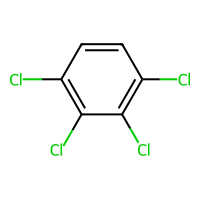
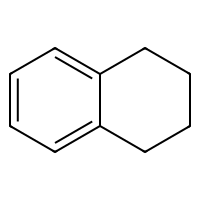
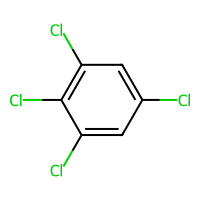
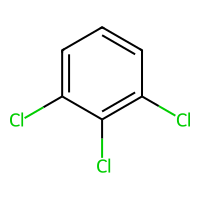
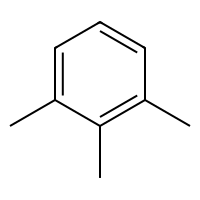
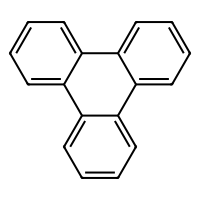
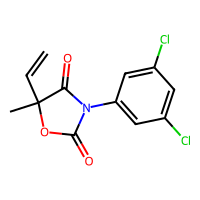
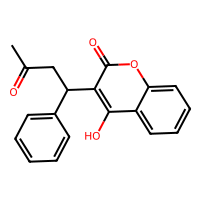
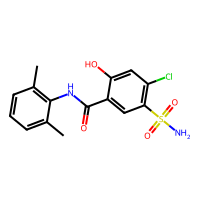
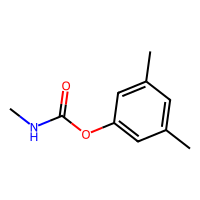

Total molecules: 1144
Molecules with benzene: 578
Molecules that satisfy all conditions: 35


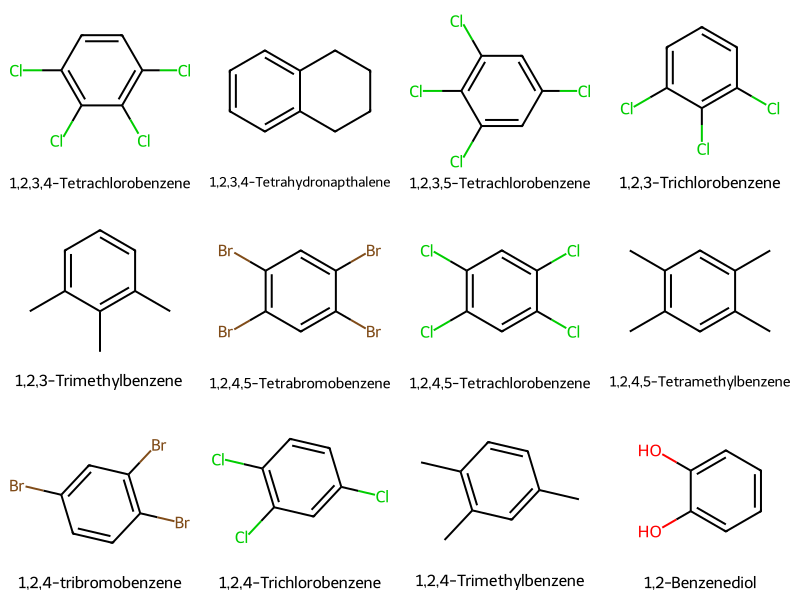

In [10]:
!pip install rdkit
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools, Draw
df=pd.read_csv("https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv")
PandasTools.AddMoleculeColumnToFrame(df,"SMILES","Molecule")
PandasTools.RenderImagesInAllDataFrames
display(df)
search_patterns={"Has_Benzene":"c1ccccc1","Has_Carbonyl":"C=O","Has_Hydroxyl": "[OH]"}
for col_name, query_smarts in search_patterns.items():
  query_mols=Chem.MolFromSmarts(query_smarts)
  df[col_name]=df["Molecule"].apply(lambda x:x.HasSubstructMatch(query_mols) if x is not None else False)
display(df[["Molecule","Has_Benzene","Has_Carbonyl","Has_Hydroxyl"]])
matched_df=df[df["Has_Benzene"]]
display(matched_df)
print("Total molecules:",len(df))
print("Molecules with benzene:",len(matched_df))
All_conditions=(df["Has_Benzene"])& (df["Has_Carbonyl"])& (df["Has_Hydroxyl"])
print("Molecules that satisfy all conditions:", All_conditions.sum())
images=Draw.MolsToGridImage(matched_df["Molecule"].head(12).tolist(),molsPerRow=4,subImgSize=(200,200),legends=matched_df["Compound ID"].head(12).tolist())
images